In [ ]:
#STEP 1: INSTALL REQUIRED LIBRARIES
!pip install pyspark
!pip install matplotlib seaborn wordcloud

In [ ]:
#STEP 2: IMPORT LIBRARIES AND INITIALIZE SPARK SESSION
from pyspark.sql import SparkSession
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import pandas as pd

spark =SparkSession.builder.appName("WordCountAnalysis").getOrCreate()

In [ ]:
#STEP 3: DOWNLOAD THE 20 NEWSGROUPS DATASET
from sklearn.datasets import fetch_20newsgroups
newsgroups = fetch_20newsgroups(subset='all')
documents = newsgroups.data

In [ ]:
#STEP 4: LOAD THE DATASET INTO SPARK RDD (RESILIENT DISTRIBUTED DATASET)
rdd=spark.sparkContext.parallelize(documents)

In [ ]:
#STEP 5: PERFORM WORD COUNT ANALYSIS
word_count = (rdd.flatMap(lambda line: line.split())
# Flatten the lines into words
                .map(lambda word: (word.lower(), 1))
# Convert words to lowercase and assign count 1
                .reduceByKey(lambda a, b: a + b))
# Aggregate counts for each word

In [ ]:
#STEP 6: CONVERT THE WORD COUNT RDD TO A PANDAS DATAFRAME FOR VISUALIZATION
word_count_dict = word_count.collect()
word_count_df = pd.DataFrame(word_count_dict,columns=["Word", "Count"])

In [ ]:
#STEP 7: SORT WORDS BY FREQUENCY
word_count_df = word_count_df.sort_values(by="Count",ascending=False)

<ipython-input-55-cccbe2cd23d9>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Count", y="Word",data=word_count_df.head(20), palette='cool')


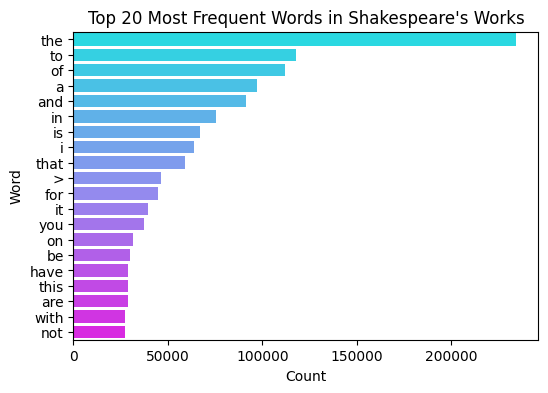

In [ ]:
#STEP 8: VISUALIZE THE TOP 20 MOST FREQUENT WORDS
plt.figure(figsize=(6, 4))
sns.barplot(x="Count", y="Word",data=word_count_df.head(20), palette='cool')
plt.title("Top 20 Most Frequent Words in Shakespeare's Works")
plt.xlabel("Count")
plt.ylabel("Word")
plt.show()

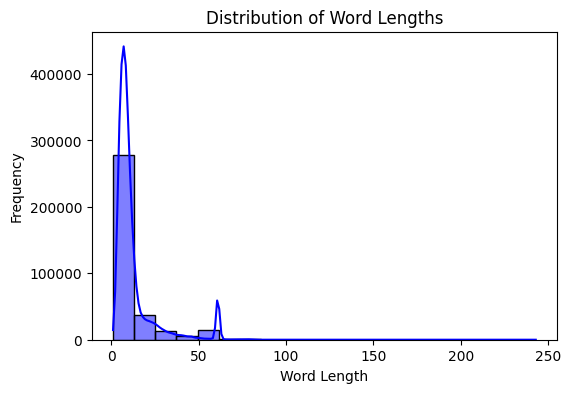

In [ ]:
#STEP 9: VISUALIZE WORD LENGTH DISTRIBUTION
word_count_df['Word Length'] =word_count_df['Word'].apply(len)
plt.figure(figsize=(6, 4))
sns.histplot(word_count_df['Word Length'], kde=True,color='blue', bins=20)
plt.title("Distribution of Word Lengths")
plt.xlabel("Word Length")
plt.ylabel("Frequency")
plt.show()

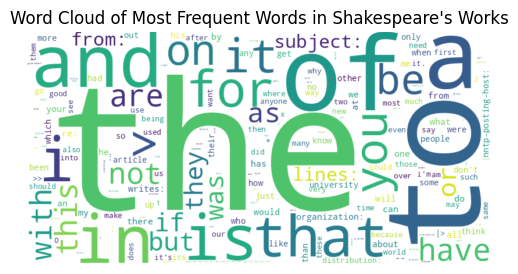

In [ ]:
#STEP 10: GENERATE A WORD CLOUD
wordcloud = WordCloud(width=800, height=400,background_color='white').generate_from_frequencies(dict(zip(word_count_df['Word'], word_count_df['Count'])))
plt.figure(figsize=(6, 4))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off') # Hide the axes
plt.title("Word Cloud of Most Frequent Words in Shakespeare's Works")
plt.show()

In [ ]:
#STEP 11: DISPLAY DATASET HEAD FOR ADDITIONAL CONTEXT
print("\nTop 5 Words from the Dataset:")
print(word_count_df.head())


Top 5 Words from the Dataset:
       Word   Count  Word Length
174610  the  234341            3
19       to  117567            2
5        of  112223            2
174615    a   97291            1
16      and   91556            3


In [ ]:
#STEP 12: STOP THE SPARK SESSION
spark.stop()